# Decision Trees by Hand
### How does the model find its questions? Let's calculate it ourselves.

Same problem as Class 19: **should the bank approve this loan?**
But today we use only **8 people**, so we can calculate on the whiteboard. Then we do the same in code.

Then we check the tree by hand too: **caught, missed, false alarms, recall, precision**.

At the end you will see: `tree.fit()` is not magic. It is just this small calculation, again and again.

## New words

| Word | Meaning in simple words |
|------|-------------------------|
| **Decision Tree** | a model that asks yes/no questions, one after another |
| **Question** | one yes/no test on one column, like "income ≤ 100?" |
| **Box** | a group of people who reached the same place in the tree |
| **Pure box** | a box where everybody has the **same** answer |
| **Gini** | a score for how **mixed** a box is. 0 = pure. 0.5 = half and half |
| **Weighted gini** | the gini of the two new boxes, added up fairly. **Lower is better** |
| **Confusion matrix** | a 2×2 table: what the model said vs what was really true |
| **Recall** | of all the real "yes" people, how many did we catch? |
| **Precision** | of all the times we said "yes", how many were really yes? |
| **Overfitting** | the model memorises the training people, so it does badly on new people |
| **Random Forest** | many trees that each give an answer, then they **vote** |
| **F1 score** | one number made from recall and precision |
| **Class weight** | how much one row of a group counts. We give the small group a bigger weight |

## The data: 8 loan applicants

| Person | Monthly income (thousand Rs) | Defaulted before? (1 = yes) | Approved? (1 = yes) |
|---|---|---|---|
| A | 50 | 1 | 0 |
| B | 70 | 0 | 0 |
| C | 90 | 0 | 0 |
| D | 110 | 0 | 1 |
| E | 140 | 0 | 1 |
| F | 160 | 0 | 1 |
| G | 180 | 1 | 0 |
| H | 200 | 0 | 1 |

**Question:** a new person has income **130** and **never defaulted**. What will our tree say?

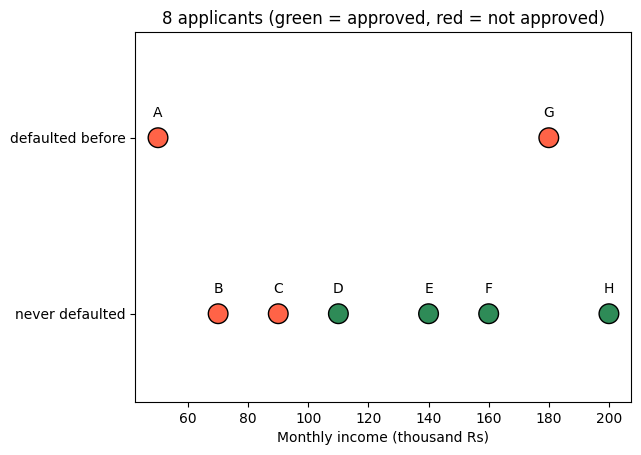

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

people = pd.DataFrame({
    "monthly_income":       [50, 70, 90, 110, 140, 160, 180, 200],
    "has_defaulted_before": [1, 0, 0, 0, 0, 0, 1, 0],
    "approved":             [0, 0, 0, 1, 1, 1, 0, 1],
}, index=list("ABCDEFGH"))

colours = people["approved"].map({0: "tomato", 1: "seagreen"})
plt.scatter(people["monthly_income"], people["has_defaulted_before"], c=colours, s=200, edgecolors="black")
for name, row in people.iterrows():
    plt.annotate(name, (row["monthly_income"], row["has_defaulted_before"]),
                 xytext=(0, 15), textcoords="offset points", ha="center")
plt.yticks([0, 1], ["never defaulted", "defaulted before"])
plt.xlabel("Monthly income (thousand Rs)")
plt.ylim(-0.5, 1.6)
plt.title("8 applicants (green = approved, red = not approved)")
plt.show()

## CONCEPT: A tree is a list of yes/no questions

A decision tree is just **if / else**, one question after another:

- "Is the income 100 or less?" → if yes, say **no**.
- If not, ask the next question...

**The big problem:** which question should we ask **first**?
There are many possible questions ("income ≤ 60?", "income ≤ 80?", "defaulted before?"...).

**The answer:** ask the question that **separates** the approved and not approved people **best**.
We need a number that tells us "how well did this question separate them?". That number is **gini**.

### ✏️ QUICK CHECK 0
Which of these can a tree use as a question?
1. "Is the income more than 100?"
2. "What is the income?"
3. "Has the person defaulted before?"

**Answer:**
1. **Yes.** It has a yes/no answer.
2. **No.** The answer is a number, not yes/no. The tree turns it into "is income ≤ 100?".
3. **Yes.** It has a yes/no answer.

## CONCEPT: Gini, how mixed is a box?

Look at a box of people. How many are **approved (yes)**, how many are **not approved (no)**?

$$\text{gini} = 1 - (\text{share of yes})^2 - (\text{share of no})^2$$

| Box | Share of yes | Share of no | gini | Meaning |
|---|---|---|---|---|
| 4 yes, 0 no | 1.0 | 0.0 | 1 − 1 − 0 = **0** | pure. Everybody is the same |
| 3 yes, 1 no | 0.75 | 0.25 | 1 − 0.5625 − 0.0625 = **0.375** | a little mixed |
| 2 yes, 2 no | 0.5 | 0.5 | 1 − 0.25 − 0.25 = **0.5** | most mixed possible |

**Remember:** low gini = good. A pure box (gini 0) needs no more questions.

In [2]:
def gini(group):
    share_yes = group.mean()                     # approved is 1 or 0, so the mean = share of yes
    return 1 - (share_yes ** 2 + (1 - share_yes) ** 2)

print("4 yes, 0 no:", gini(pd.Series([1, 1, 1, 1])))
print("3 yes, 1 no:", gini(pd.Series([1, 1, 1, 0])))
print("2 yes, 2 no:", gini(pd.Series([1, 1, 0, 0])))

4 yes, 0 no: 0.0
3 yes, 1 no: 0.375
2 yes, 2 no: 0.5


### ✏️ QUICK CHECK 1
A box has **1 yes** and **3 no**. What is its gini? Do it by hand first, then check with code.

**Answer:** share of yes = 0.25, share of no = 0.75. gini = 1 − 0.0625 − 0.5625 = **0.375**.

## Step 1: How mixed is the whole group?

All 8 people: **4 approved, 4 not approved**. Half and half.

$$\text{gini} = 1 - 0.5^2 - 0.5^2 = 0.5$$

This is the **starting point**. A good question must bring the gini **below 0.5**.

In [3]:
print("gini of all 8 people:", gini(people["approved"]))

gini of all 8 people: 0.5


## Step 2: Try one question: "income ≤ 100?"

The question cuts the people into two boxes:

| Box | Who | Approved | Not approved | gini |
|---|---|---|---|---|
| **Box 1** (income ≤ 100) | A, B, C | 0 | 3 | 1 − 0 − 1 = **0** (pure!) |
| **Box 2** (income > 100) | D, E, F, G, H | 4 | 1 | 1 − 0.8² − 0.2² = **0.32** |

Two boxes, two gini numbers. We need **one** number for the question.
Box 2 has more people (5), so it should count more. We use a **weighted** average:

$$\text{weighted gini} = \frac{3}{8} \times 0 + \frac{5}{8} \times 0.32 = 0 + 0.2 = \mathbf{0.2}$$

0.2 is much lower than 0.5. This is a **good** question.

In [4]:
def weighted_gini(data, question_is_true):
    left = data[question_is_true]["approved"]       # Box 1: people for whom the question is true
    right = data[~question_is_true]["approved"]     # Box 2: everybody else
    n = len(data)
    return len(left) / n * gini(left) + len(right) / n * gini(right)

question = people["monthly_income"] <= 100
print("Box 1:", list(people[question].index), " gini =", gini(people[question]["approved"]))
print("Box 2:", list(people[~question].index), " gini =", round(gini(people[~question]["approved"]), 2))
print("weighted gini of 'income <= 100':", round(weighted_gini(people, question), 2))

Box 1: ['A', 'B', 'C']  gini = 0.0
Box 2: ['D', 'E', 'F', 'G', 'H']  gini = 0.32
weighted gini of 'income <= 100': 0.2


## Step 3: Try ALL the questions, pick the lowest

The tree does not guess. It tries **every** question and keeps the best one.

For income, we try a cut **halfway between two neighbours**. For example, halfway between 50 and 70 is 60, and halfway between 90 and 110 is 100. So the cuts are 60, 80, 100, 125, 150, 170, 190.
We also try "defaulted before?".

In [5]:
rows = []
for limit in [60, 80, 100, 125, 150, 170, 190]:
    mask = people["monthly_income"] <= limit
    rows.append({"question": "income <= " + str(limit), "weighted gini": round(weighted_gini(people, mask), 3)})

mask = people["has_defaulted_before"] == 1
rows.append({"question": "defaulted before?", "weighted gini": round(weighted_gini(people, mask), 3)})

scores = pd.DataFrame(rows)
scores

,question,weighted gini
0,income <= 60,0.429
1,income <= 80,0.333
2,income <= 100,0.200
3,income <= 125,0.375
4,income <= 150,0.467
5,income <= 170,0.500
6,income <= 190,0.429
7,defaulted before?,0.333


**The lowest is 0.2: "income ≤ 100?".** That is the **first question** (the root) of our tree.

Why is it the best? Because everybody with income ≤ 100 is "not approved". One whole box is **pure**. We are done with that box.

### ✏️ QUICK CHECK 2
Which question is the **second best**? What is its weighted gini?

**Answer:** "defaulted before?" with **0.333**. (And "income ≤ 80" is also 0.333.)

## Step 4: Draw the first question

The question "income ≤ 100" is a **vertical line** between our people.

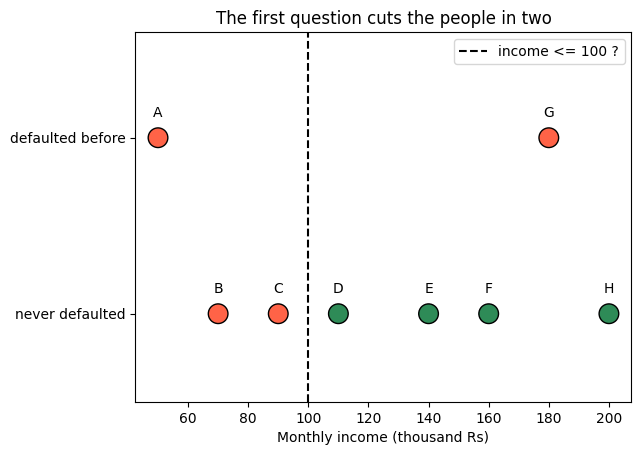

In [6]:
plt.scatter(people["monthly_income"], people["has_defaulted_before"], c=colours, s=200, edgecolors="black")
for name, row in people.iterrows():
    plt.annotate(name, (row["monthly_income"], row["has_defaulted_before"]),
                 xytext=(0, 15), textcoords="offset points", ha="center")
plt.axvline(100, color="black", linestyle="--", label="income <= 100 ?")
plt.yticks([0, 1], ["never defaulted", "defaulted before"])
plt.xlabel("Monthly income (thousand Rs)")
plt.ylim(-0.5, 1.6)
plt.legend()
plt.title("The first question cuts the people in two")
plt.show()

**Look:** on the left of the line, all 3 people are red. Pure.
On the right, there are 4 green and 1 red (person G). It is **not pure**, so the tree asks **again**.

## Step 5: Ask again, only in the box that is not pure

Now we only look at the 5 people on the right: D, E, F, G, H. We do the **same calculation**:

In [7]:
right_box = people[people["monthly_income"] > 100]
print("gini of this box:", round(gini(right_box["approved"]), 2))

q1 = right_box["has_defaulted_before"] == 1
q2 = right_box["monthly_income"] <= 170
print("weighted gini of 'defaulted before?':", round(weighted_gini(right_box, q1), 2))
print("weighted gini of 'income <= 170?'   :", round(weighted_gini(right_box, q2), 2))

gini of this box: 0.32
weighted gini of 'defaulted before?': 0.0
weighted gini of 'income <= 170?'   : 0.2


**"Defaulted before?" gives 0.** Both new boxes are pure:
- defaulted before = yes → only G → **not approved**
- defaulted before = no → D, E, F, H → all **approved**

Every box is pure. The tree stops. (A tree with 2 questions in a row has `max_depth = 2`.)

## Step 6: Our tree

```
          Income <= 100 ?
          /            \
        YES             NO
         |               |
   NOT APPROVED    Defaulted before ?
     (A, B, C)       /           \
                   YES            NO
                    |              |
              NOT APPROVED      APPROVED
                 (G)          (D, E, F, H)
```

**Note:** YES / NO on the branches is the answer to the **question** (is income ≤ 100?). It is not the loan decision.

A tree is just `if` and `else`. We can write it as a small function:

In [8]:
def my_tree(income, defaulted):
    if income <= 100:
        return 0                 # not approved
    if defaulted == 1:
        return 0                 # not approved
    return 1                     # approved

print("income 130, never defaulted:", my_tree(130, 0), "(1 = approved)")

income 130, never defaulted: 1 (1 = approved)


**Answer to our question:** income 130 is more than 100, and the person never defaulted → **APPROVED**.

### ✏️ QUICK CHECK 3
A person has income **120** and **defaulted before**. Follow the tree by hand. What does it say? Then check with `my_tree(120, 1)`.

**Answer:** income 120 > 100 → ask "defaulted before?" → yes → **NOT APPROVED** (0).

## Step 7: Now let scikit-learn do it

Same 8 people. Does the model find the same questions?

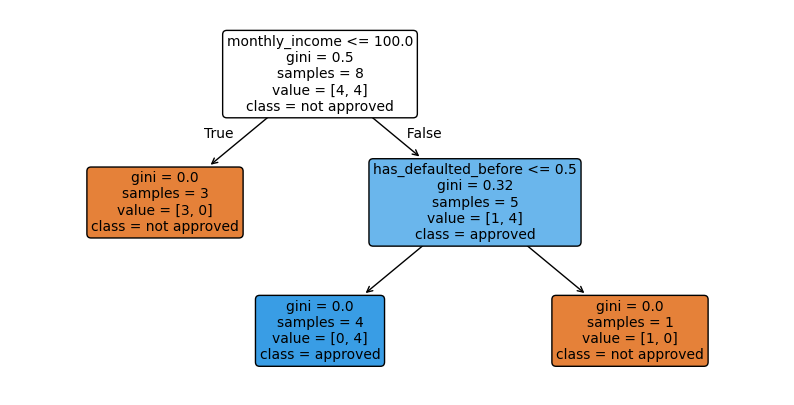

In [25]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

features = ["monthly_income", "has_defaulted_before"]
tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(people[features], people["approved"])

plt.figure(figsize=(10, 5))
plot_tree(tree, feature_names=features, class_names=["not approved", "approved"], filled=True, rounded=True, fontsize=10)
plt.show()

**Same questions, same numbers:**
- first question: `monthly_income <= 100.0`. gini = 0.5 at the top, 8 people, `value = [4, 4]` (4 not approved, 4 approved).
- the left box: gini = 0, pure. The right box: gini = 0.32, `value = [1, 4]` (1 not approved, 4 approved).
- second question: `has_defaulted_before <= 0.5`. Both boxes have gini = 0.

So when we write `tree.fit(...)`, the computer does exactly our table: try every question, keep the lowest weighted gini, repeat in every box that is not pure.

## Step 8: Check the tree by hand

A tree that is right on the people it learned from is not a surprise. We need **new** people, hidden from the tree.

Here are **8 new people** (the **test** people). We know the real answer. We ask our tree, and then compare.

In [10]:
test = pd.DataFrame({
    "monthly_income":       [70, 85, 120, 150, 170, 130, 190, 105],
    "has_defaulted_before": [0, 0, 0, 0, 1, 0, 0, 0],
    "approved":             [0, 1, 1, 1, 0, 0, 1, 0],
}, index=["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8"])

def explain(income, defaulted):
    # The same path as my_tree, but written out in words
    if income <= 100:
        return "income " + str(income) + " <= 100  -> NOT APPROVED"
    if defaulted == 1:
        return "income " + str(income) + " > 100, defaulted before  -> NOT APPROVED"
    return "income " + str(income) + " > 100, never defaulted  -> APPROVED"

test["tree says"] = [my_tree(i, d) for i, d in zip(test["monthly_income"], test["has_defaulted_before"])]
test["how the tree decided"] = [explain(i, d) for i, d in zip(test["monthly_income"], test["has_defaulted_before"])]
test["right?"] = test["approved"] == test["tree says"]
test

,monthly_income,has_defaulted_before,approved,tree says,how the tree decided,right?
P1,70,0,0,0,income 70 <= 100 -> NOT APPROVED,True
P2,85,0,1,0,income 85 <= 100 -> NOT APPROVED,False
P3,120,0,1,1,"income 120 > 100, never defaulted -> APPROVED",True
P4,150,0,1,1,"income 150 > 100, never defaulted -> APPROVED",True
P5,170,1,0,0,"income 170 > 100, defaulted before -> NOT APP...",True
P6,130,0,0,1,"income 130 > 100, never defaulted -> APPROVED",False
P7,190,0,1,1,"income 190 > 100, never defaulted -> APPROVED",True
P8,105,0,0,1,"income 105 > 100, never defaulted -> APPROVED",False


In [79]:
test["sklearn tree says"] = tree.predict(test[features])
test[["monthly_income", "has_defaulted_before", "approved", "tree says", "sklearn tree says"]]

,monthly_income,has_defaulted_before,approved,tree says,sklearn tree says
P1,70,0,0,0,0
P2,85,0,1,0,0
P3,120,0,1,1,1
P4,150,0,1,1,1
P5,170,1,0,0,0
P6,130,0,0,1,1
P7,190,0,1,1,1
P8,105,0,0,1,1


### Does the scikit-learn tree give the same answers?

In Step 7 we trained `tree` with `fit()`. Now we use it to **predict** the same 8 new people with `tree.predict()`.

Look at the last two columns: `tree says` (our hand tree) and `sklearn tree says` (the model). **They are the same for all 8 people.** So `fit()` and `predict()` are just our small tree, done by the computer.

### How did the tree predict for the new people?

For each new person, the tree did **only** what we drew in Step 6. It asked "income ≤ 100?", and if needed, "defaulted before?". It never looked at the real answer.

| Person | Walk through the tree | Tree says | Real answer | |
|---|---|---|---|---|
| P1 | 70 ≤ 100 | not approved | not approved | ✅ right |
| P2 | 85 ≤ 100 | not approved | **approved** | ❌ missed |
| P3 | 120 > 100, never defaulted | approved | approved | ✅ right |
| P4 | 150 > 100, never defaulted | approved | approved | ✅ right |
| P5 | 170 > 100, defaulted before | not approved | not approved | ✅ right |
| P6 | 130 > 100, never defaulted | approved | **not approved** | ❌ false alarm |
| P7 | 190 > 100, never defaulted | approved | approved | ✅ right |
| P8 | 105 > 100, never defaulted | approved | **not approved** | ❌ false alarm |

## ✅ Conclusion of our loan problem

- **Our question:** income 130, never defaulted. The tree says **APPROVED**.
- **On 8 new people the tree was right 5 times and wrong 3 times** (accuracy 5 ÷ 8 = 0.625).
- **Why the 3 mistakes?**
  - **P2** has a low income (85) but was approved. The tree's rule "income ≤ 100 → reject" is too strict for this person.
  - **P6 and P8** have a good income and never defaulted, but the bank still rejected them. The tree sees only **2 columns**, so it cannot see the real reason (maybe a big loan, or few years in the job).
- **Why is it not better?** The tree learned from only **8 people** and 2 columns. A rule built on so little data cannot be perfect.
- **What to do:** use many more people and more columns. That is the real file with 400 loans in Step 9 below.

Now let's count these answers properly, with the confusion matrix.

## Why do we need a confusion matrix?

**The problem with one number.** Accuracy says: "the tree was right 5 times out of 8." But it does not say **what kind** of mistakes the tree made.

A tree can make **two different mistakes**:

| Mistake | What happened | What it costs the bank |
|---|---|---|
| **Missed** | a good person was **rejected** | the bank loses a good customer |
| **False alarm** | a bad person was **approved** | the bank may **lose its money** |

These two mistakes are **not the same**. But accuracy counts them both as just "wrong". It hides the difference.

**The confusion matrix is a small table that separates the mistakes.** It is like a marksheet: the total marks (accuracy) tell you only the result, but the marksheet shows which subject went wrong.

**Why we need it here:**
1. To see **which** mistake the tree makes more.
2. To calculate **recall**, **precision** and **F1**. They all come from these 4 boxes.
3. To avoid the **accuracy trap** on rare cases like fraud (you will see it below).

### ✏️ QUICK CHECK 4
The tree **approves** a person, but the person really **does not repay**. Which box is it: caught, missed, false alarm or correct no?

**Answer:** the tree said **yes** and the real answer is **no** → **false alarm**.

## The confusion matrix: 4 kinds of answers

Count the 8 people into 4 boxes (here, **yes = approved**). Each box has a simple name and a short name used by everybody (TP, FN, FP, TN):

| Box | Short name | Real | Tree said | People | How many |
|---|---|---|---|---|---|
| ✅ **caught** | **TP** (true positive) | yes | yes | P3, P4, P7 | **3** |
| ❌ **missed** | **FN** (false negative) | yes | no | P2 | **1** |
| ⚠️ **false alarm** | **FP** (false positive) | no | yes | P6, P8 | **2** |
| ✅ **correct no** | **TN** (true negative) | no | no | P1, P5 | **2** |

**How to remember the short names:** the second word is what the **tree said** (positive = yes, negative = no). The first word says if the tree was **right** (true) or **wrong** (false).
- **True positive:** the tree said yes, and it was right.
- **False positive:** the tree said yes, but it was wrong (a false alarm).
- **True negative:** the tree said no, and it was right.
- **False negative:** the tree said no, but it was wrong (a missed person).

```
                          TREE SAID: no                  TREE SAID: yes
REALLY no  (4 people)     2  TN  ✅ correct no           2  FP  ⚠️ false alarm
REALLY yes (4 people)     1  FN  ❌ missed               3  TP  ✅ caught
```

In [11]:
real = test["approved"]
said = test["tree says"]

caught = ((real == 1) & (said == 1)).sum()
missed = ((real == 1) & (said == 0)).sum()
false_alarm = ((real == 0) & (said == 1)).sum()
correct_no = ((real == 0) & (said == 0)).sum()
print("caught:", caught, " missed:", missed, " false alarms:", false_alarm, " correct no:", correct_no)

from sklearn.metrics import confusion_matrix
print(confusion_matrix(real, said))

caught: 3  missed: 1  false alarms: 2  correct no: 2
[[2 2]
 [1 3]]


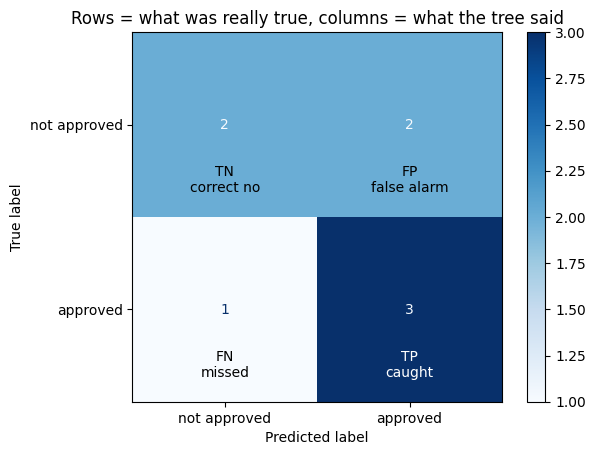

In [81]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay.from_predictions(
    real, said, display_labels=["not approved", "approved"], cmap="Blues")

# Write the short name inside each box (white text on the dark box)
names = [["TN\ncorrect no", "FP\nfalse alarm"],
         ["FN\nmissed", "TP\ncaught"]]
for r in range(2):
    for c in range(2):
        colour = "white" if (r, c) == (1, 1) else "black"
        disp.ax_.text(c, r + 0.3, names[r][c], ha="center", va="center", fontsize=10, color=colour)

plt.title("Rows = what was really true, columns = what the tree said")
plt.show()

**How to read the picture:**
- **Rows** = what was really true. **Columns** = what the tree said.
- **Top-left, TN (2)** and **bottom-right, TP (3)** are the correct answers.
- **Top-right, FP (2)** is a **false alarm**: the tree said yes, but the real answer is no.
- **Bottom-left, FN (1)** is a **missed** person: the tree said no, but the real answer is yes.
- The darker the blue, the more people in the box.

## Three scores, from the 4 boxes

| Score | Question | Formula | Our numbers |
|---|---|---|---|
| **Accuracy** | how many answers were right? | (caught + correct no) ÷ all | (3 + 2) ÷ 8 = **0.625** |
| **Recall** | of all real yes, how many did we catch? | caught ÷ (caught + missed) | 3 ÷ (3 + 1) = **0.75** |
| **Precision** | when we said yes, how often were we right? | caught ÷ (caught + false alarms) | 3 ÷ (3 + 2) = **0.60** |

In [12]:
from sklearn.metrics import accuracy_score, recall_score, precision_score

print("Accuracy by hand :", (caught + correct_no) / len(test))
print("Recall by hand   :", caught / (caught + missed))
print("Precision by hand:", caught / (caught + false_alarm))

print("\nscikit-learn:")
print("Accuracy :", accuracy_score(real, said))
print("Recall   :", recall_score(real, said))
print("Precision:", precision_score(real, said))

Accuracy by hand : 0.625
Recall by hand   : 0.75
Precision by hand: 0.6

scikit-learn:
Accuracy : 0.625
Recall   : 0.75
Precision: 0.6


## F1 score: one number for recall and precision together

**Why do we need it?** Now we have two scores, recall (0.75) and precision (0.60). When we compare two trees, one tree may win on recall and the other on precision. Which one is better? We want **one number** to decide.

**F1 is that number.** It mixes recall and precision, and it is **low if either one is low**.

$$F1 = \frac{2 \times \text{precision} \times \text{recall}}{\text{precision} + \text{recall}}$$

**Our tree:** F1 = 2 × 0.60 × 0.75 ÷ (0.60 + 0.75) = 0.9 ÷ 1.35 = **0.67**

**Why not a normal average?** Take a lazy model that says "yes" to everybody. Recall = 1.0 (it catches every real yes), but precision is low, about 0.5. The normal average is 0.75, which looks good. But F1 = 2 × 0.5 × 1.0 ÷ 1.5 = **0.67**. F1 is stricter. You cannot hide a bad score behind a good one.

**Should we calculate F1 on a decision tree?** **Yes.** F1 does not belong to the tree. It is calculated from the **answers** of any model: tree, KNN, Logistic Regression, Random Forest. We only need two lists: the real answers and the model's answers. So we can use it to compare all our models fairly.

**When to use F1:**
- The data is **imbalanced** (fraud, disease), so accuracy lies.
- You want **one number** to compare models.

**Only for classification.** F1 needs a confusion matrix (groups). For numbers like house prices (regression) use MAE or MSE, below.

**When F1 is not enough:** it treats recall and precision as equally important. If one mistake is clearly worse (missing a fraud), look at **recall** itself too.

In [83]:
from sklearn.metrics import f1_score

precision = caught / (caught + false_alarm)
recall = caught / (caught + missed)

print("F1 by hand   :", round(2 * precision * recall / (precision + recall), 2))
print("F1 scikit-learn:", round(f1_score(real, said), 2))

F1 by hand   : 0.67
F1 scikit-learn: 0.67


**Same number both ways: 0.67.** F1 is not magic. It is a formula on top of recall and precision.

**The fraud example below, with F1:**

| | Recall | Precision | F1 |
|---|---|---|---|
| Lazy model | 0 | (nothing caught) | **0** |
| Normal tree | 0.25 | 0.86 | **0.39** |
| Balanced tree | 0.79 | 0.33 | **0.46** |

The lazy model had 94% accuracy, but its F1 is **0**. F1 shows it is useless.

### ✏️ QUICK CHECK 5
A model has recall = 0.9 and precision = 0.1. Is F1 high or low? Why?

**Answer:** low. F1 = 2 × 0.1 × 0.9 ÷ 1.0 = **0.18**. F1 is low when **either** score is low.

## ✅ Conclusion: what accuracy, recall, precision and F1 tell us

**1. By hand and scikit-learn give the same numbers.** The functions are not magic. They only count the 4 boxes (caught, missed, false alarms, correct no) and divide.

**2. Each score answers a different question:**

| Score | Our number | In simple words |
|---|---|---|
| **Accuracy** | 0.625 | the tree was right for **5 of 8** people |
| **Recall** | 0.75 | of the **4 really approved** people, it found **3** (missed 1) |
| **Precision** | 0.6 | of the **5 times** it said "approved", it was right **3** times (2 false alarms) |

**3. One score is not enough.** The same tree looks "OK" on accuracy (0.625) but has a different story on recall and precision.

**4. Which score matters most depends on the problem.** Ask: *which mistake is worse?*
- Missing a real case is worse (fraud, disease) → look at **recall**.
- A false alarm is worse (spam filter) → look at **precision**.
- Both mistakes cost the same → **accuracy** is OK.

**5. F1 puts recall and precision in one number** (next section), so we can compare models easily.

### ✏️ QUICK CHECK 6: The lazy model
A lazy model says **"no"** (0) for all 8 new people. Count the 4 boxes by hand. What are its accuracy and recall?

**Answer:** it says no to everyone, so caught = 0, missed = 4, false alarms = 0, correct no = 4.
Accuracy = 4 ÷ 8 = **0.5**. Recall = 0 ÷ 4 = **0**. It caught nobody.

## The accuracy trap, by hand

Here half of the people are "yes", so the lazy model gets only 0.5. Now look at **fraud**:

> A bank has **100 payments**. Only **6** are fraud. A lazy model says **"normal"** for every payment.

| Score | Calculation | Result |
|---|---|---|
| Accuracy | 94 correct ÷ 100 | **0.94** (looks great!) |
| Recall | 0 frauds caught ÷ 6 frauds | **0** (useless!) |

**When one group is small, accuracy can lie.** Always compare with the lazy model, and look at recall.

## For numbers: MAE and MSE, by hand

For house prices we do not count right/wrong. We look at the **error** (the residual from the Linear Regression file).
Three houses are wrong by **2, 2 and 10 lakh**:

| | Calculation | Result |
|---|---|---|
| **MAE** (average error) | (2 + 2 + 10) ÷ 3 | **4.7** |
| **MSE** (average of squared errors) | (4 + 4 + 100) ÷ 3 | **36** |

Squaring makes the **big mistake** (10) count much more. Use MAE to explain the error to people.

In [13]:
errors = np.array([2, 2, 10])
print("MAE:", round(np.abs(errors).mean(), 1))
print("MSE:", round((errors ** 2).mean(), 1))

MAE: 4.7
MSE: 36.0


## Step 9: In a real project, we split first

8 people is too few, but we only wanted to see **how the tree is built**.

**Now the real file: 400 loan applications** (`loans.csv`, the same as Class 19).
- **Train** (80%): the tree learns its questions from these people.
- **Test** (20%): hidden. We check the tree on them.

**Using Colab?** Upload `loans.csv` first.

In [14]:
from sklearn.model_selection import train_test_split

loans = pd.read_csv("loans.csv")
X = loans[["monthly_income", "loan_amount", "years_in_job", "has_defaulted_before"]]
y = loans["approved"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", len(X_train), " Test:", len(X_test))

Train: 320  Test: 80


### See the questions the model made

Nobody gave the tree these questions. `fit()` made them from the 320 training people.
Let's draw the tree (`plot_tree`) and also print it as text (`export_text`):

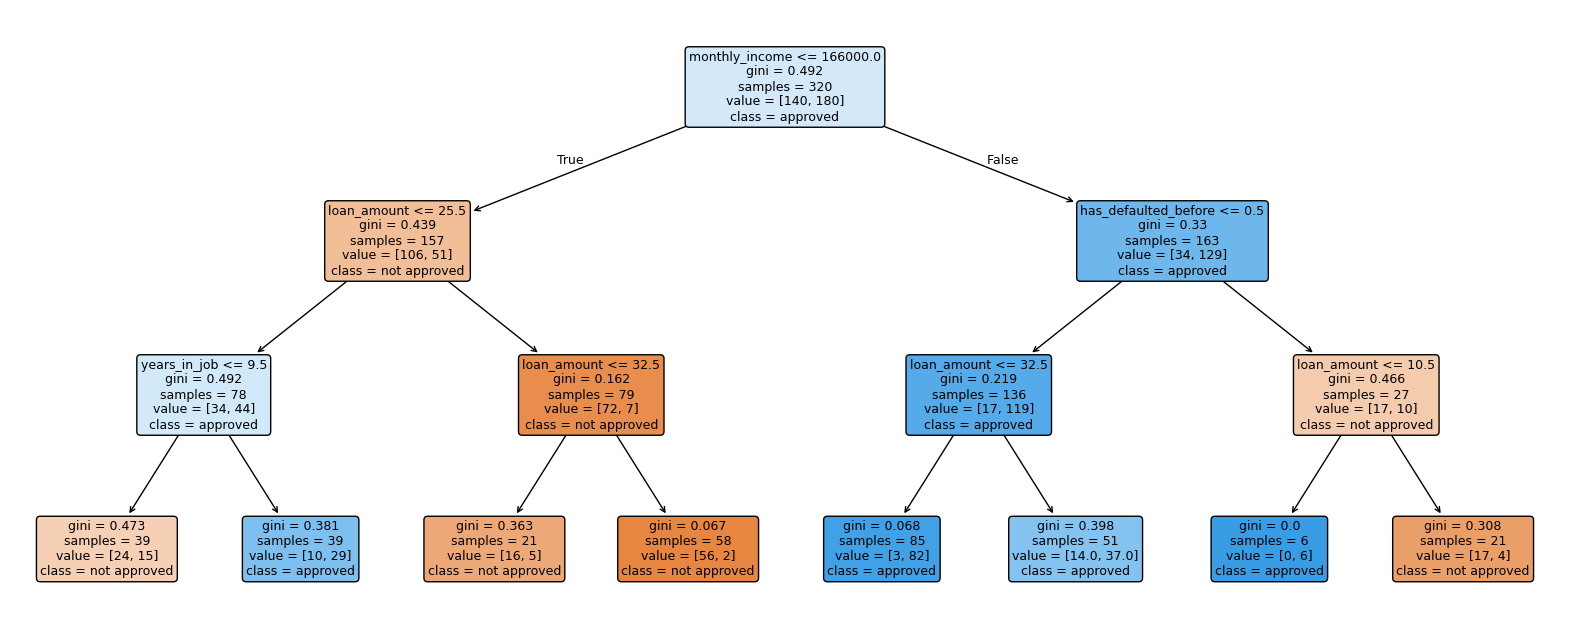

|--- monthly_income <= 166000.00
|   |--- loan_amount <= 25.50
|   |   |--- years_in_job <= 9.50
|   |   |   |--- class: 0
|   |   |--- years_in_job >  9.50
|   |   |   |--- class: 1
|   |--- loan_amount >  25.50
|   |   |--- loan_amount <= 32.50
|   |   |   |--- class: 0
|   |   |--- loan_amount >  32.50
|   |   |   |--- class: 0
|--- monthly_income >  166000.00
|   |--- has_defaulted_before <= 0.50
|   |   |--- loan_amount <= 32.50
|   |   |   |--- class: 1
|   |   |--- loan_amount >  32.50
|   |   |   |--- class: 1
|   |--- has_defaulted_before >  0.50
|   |   |--- loan_amount <= 10.50
|   |   |   |--- class: 1
|   |   |--- loan_amount >  10.50
|   |   |   |--- class: 0



In [15]:
from sklearn.tree import plot_tree, export_text

small_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
small_tree.fit(X_train, y_train)

plt.figure(figsize=(20, 8))
plot_tree(small_tree, feature_names=X.columns, class_names=["not approved", "approved"],
          filled=True, rounded=True, fontsize=9)
plt.show()

print(export_text(small_tree, feature_names=list(X.columns)))

**How to read it:**
- The **top box** is the first question. It is the column the tree found most useful.
- For each question: **true → go left**, **false → go right**.
- The boxes at the **bottom** give the answer (`class = approved` or `not approved`).
- **Colour:** orange = mostly not approved, blue = mostly approved. A darker colour = more sure.
- The text version is the same tree. Each `|---` is a question. `class: 1` means approved, `class: 0` means not approved.

**Try it yourself:** pick any applicant, start at the top box, and answer each question. The bottom box you reach is the tree's answer.

### Small tree or big tree?

`max_depth` is the most questions in a row. What if we let the tree ask **as many as it wants**?

In [16]:
for depth in [3, None]:                          # None = no limit
    t = DecisionTreeClassifier(max_depth=depth, random_state=42)
    t.fit(X_train, y_train)
    print("max_depth =", depth,
          "| questions in a row:", t.get_depth(),
          "| train:", round(accuracy_score(y_train, t.predict(X_train)), 2),
          "| test:", round(accuracy_score(y_test, t.predict(X_test)), 2))

max_depth = 3 | questions in a row: 3 | train: 0.83 | test: 0.78
max_depth = None | questions in a row: 11 | train: 1.0 | test: 0.74


**How to read it:**
- **Small tree** (`max_depth=3`): the train score and the test score are **close**. A small gap.
- **Big tree** (no limit): the train score is **1.0**. Every training person sits alone in a pure box, so the tree **memorised** them. But the test score is **lower** than the small tree's.
- **The gap** between train and test is the sign of **overfitting**.

## ✅ Conclusion: a bigger tree is not a better tree

| | Small tree | Big tree |
|---|---|---|
| Questions in a row | few (3) | many (10 or more) |
| Train score | high | **1.0** (memorised) |
| Test score | good | **lower** |
| Gap (train − test) | small | **big** |

**What we learn:**
1. A deep tree **overfits**. It memorises the training people, including strange cases, and does worse on **new** people.
2. Keep the tree **small** with `max_depth` (3 to 5 questions).
3. **Judge a model by the test score**, never the train score. Train 1.0 means nothing by itself.

**Like a student:** one memorised last year's paper, so 100% on that paper, but fails the new exam. The other understood the topic, and does well on both.

### ✏️ QUICK CHECK 7
1. Why does the big tree get 1.0 on train?
2. Which score do we report: train or test?

**Answer:**
1. It keeps asking questions until every training person is alone in a pure box. It memorised them.
2. The **test** score. It is the honest one.

## Why Random Forest? Many trees vote

**Where we are (from the small tree vs big tree table):**
- One **small** tree (depth 3): safe, but it may be too simple. Test score 0.78.
- One **big** tree (no limit): detailed, but it **memorises**. Test score 0.74.
- Also, **one tree is not steady**. Change a few training people, and the tree can ask very different questions.

**The idea:** do not trust **one** tree. Build **many different trees**, and let them **vote**. One tree's strange mistake gets outvoted by the others.

**Important: the trees inside a Random Forest are big trees** (no `max_depth` limit). Alone, each big tree memorises its own training part and makes its own strange mistakes. But every tree sees a **different random part** of the data, so every tree memorises **different** strange cases. When they vote, these strange mistakes **cancel out**.

So the forest takes the weakness of the big tree (memorising) and fixes it with many votes.

For a new person, **all trees vote**:

| Tree | Says |
|---|---|
| Tree 1 | approve |
| Tree 2 | reject |
| Tree 3 | approve |
| Tree 4 | approve |
| Tree 5 | reject |
| **Vote: 3 approve, 2 reject** | **approve** |

Like asking 100 doctors instead of 1.

In [17]:
from sklearn.ensemble import RandomForestClassifier

models = {
    "small tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "big tree (no limit) ": DecisionTreeClassifier(random_state=42),
    "random forest       ": RandomForestClassifier(n_estimators=100, random_state=42),   # 100 big trees
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "| train:", round(accuracy_score(y_train, model.predict(X_train)), 2),
          "| test:", round(accuracy_score(y_test, model.predict(X_test)), 2))

small tree (depth 3) | train: 0.83 | test: 0.78
big tree (no limit)  | train: 1.0 | test: 0.74
random forest        | train: 1.0 | test: 0.78


**How to read it:**
- **Big tree → Random Forest: 0.74 → 0.78.** The forest is made of big trees, but the vote fixed the memorising problem. This is exactly why we use a forest.
- **Random Forest vs small tree: both about 0.78.** On this small data (400 people, 4 columns), one small tree is already good enough. A forest usually wins when the data is bigger and more complex.
- **The forest's train score is 1.0 too.** Each tree still memorises its part. That is fine, because we judge by the **test** score.
- No model is always the best. We try a few and compare them on the same test data.

### Let's look inside the forest

**Same data as before:** this forest is trained on the same `loans.csv` split as the small tree and the big tree (the same `X_train` and `y_train`, 320 loan applicants). It is tested on the same 80 hidden applicants.

A forest has 100 trees. We cannot draw all of them, so here are the first 3 (only the top 3 levels):

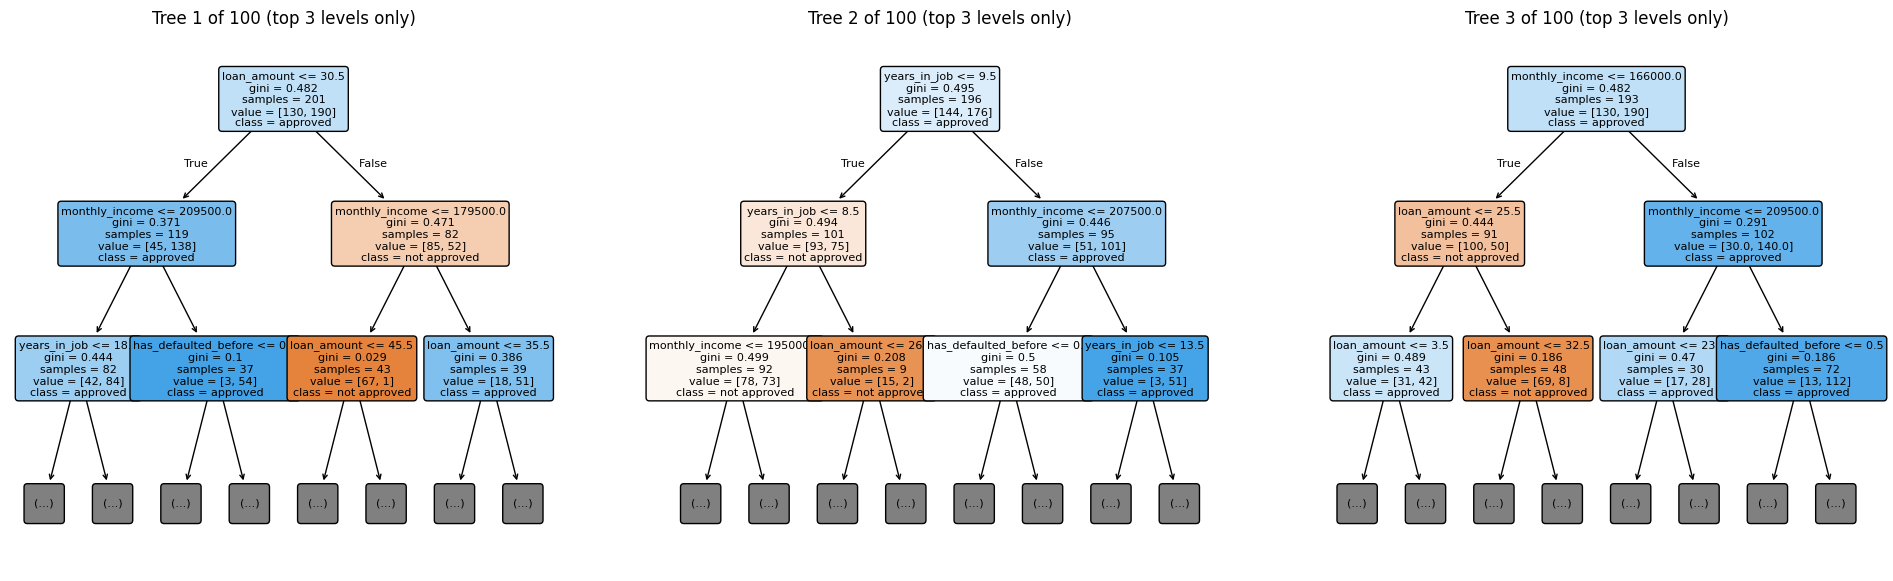

In [89]:
from sklearn.tree import plot_tree

forest = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for i in range(3):
    plot_tree(forest.estimators_[i], max_depth=2, feature_names=X.columns,
              class_names=["not approved", "approved"], filled=True, rounded=True, fontsize=8, ax=axes[i])
    axes[i].set_title("Tree " + str(i + 1) + " of 100 (top 3 levels only)")
plt.show()

**Look:** the three trees are **different**. Tree 1 asks `loan_amount` first, Tree 2 asks `years_in_job`, Tree 3 asks `monthly_income`. Each tree saw a different random part of the 320 people, so each one learned different questions. This is why their mistakes do not all happen at the same place.

**How to read a box: `samples` and `value`**
- `samples` = how many **different people** reached this box.
- `value = [no, yes]` = how many of them are "not approved" and how many are "approved". `class` is the bigger number.

**Why does `value` add up to more than `samples` in a forest?** Each tree gets its **own pile** of people, picked at random **with repeats**, like a teacher photocopying files:

| Tree | Its pile (5 files) | `samples` (different people) | `value` adds up to (files) |
|---|---|---|---|
| Tree 1 | A, **B, B**, D, E | 4 | 5 |
| Tree 2 | **A, A**, **C, C**, E | 3 | 5 |

A repeated person is counted **once** in `samples`, but **every time** in `value`. This also makes each tree's pile different, so each tree asks different questions. In the single small tree there are no repeats, so `value` adds up to `samples`.

Now let's see the **vote** for one hidden test person, and which columns the forest used most:

Approve votes: 95  Reject votes: 5
Forest says: 1  Real answer: 1


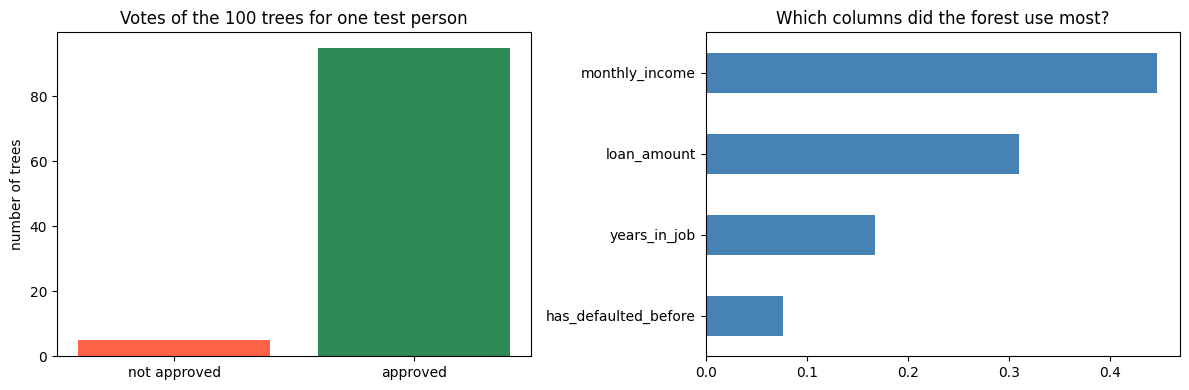

In [90]:
import numpy as np

person = X_test.iloc[[0]]                                      # the first hidden test person
votes = np.array([t.predict(person.values)[0] for t in forest.estimators_])
approve_votes = int((votes == 1).sum())
print("Approve votes:", approve_votes, " Reject votes:", 100 - approve_votes)
print("Forest says:", forest.predict(person)[0], " Real answer:", y_test.iloc[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["not approved", "approved"], [100 - approve_votes, approve_votes], color=["tomato", "seagreen"])
axes[0].set_title("Votes of the 100 trees for one test person")
axes[0].set_ylabel("number of trees")
pd.Series(forest.feature_importances_, index=X.columns).sort_values().plot.barh(ax=axes[1], color="steelblue")
axes[1].set_title("Which columns did the forest use most?")
plt.tight_layout()
plt.show()

**How to read it:**
- **Left (votes):** 95 trees said approved and 5 said not approved. The majority wins, so the forest says **approved**. This is the vote table from above, with 100 trees. The 5 wrong trees are outvoted.
- **Right (importance):** `monthly_income` matters most, then `loan_amount`, then `years_in_job`, and `has_defaulted_before` the least. A single tree gives only its own questions. The forest gives an average over 100 trees, so this is a steadier answer.

## ✅ Conclusion: small tree vs big tree vs Random Forest

Same data (`loans.csv`), same split, same 80 hidden test people. Here are all the scores together:

In [91]:
from sklearn.metrics import f1_score

rows = []
for name, model in models.items():
    train_acc = round(accuracy_score(y_train, model.predict(X_train)), 2)
    pred = model.predict(X_test)
    test_acc = round(accuracy_score(y_test, pred), 2)
    rows.append({"model": name.strip(), "train": train_acc, "test": test_acc,
                 "gap": round(train_acc - test_acc, 2),
                 "recall": round(recall_score(y_test, pred), 2),
                 "precision": round(precision_score(y_test, pred), 2),
                 "F1": round(f1_score(y_test, pred), 2)})
pd.DataFrame(rows)

,model,train,test,gap,recall,precision,F1
0,small tree (depth 3),0.83,0.78,0.05,0.82,0.79,0.80
1,big tree (no limit),1.00,0.74,0.26,0.80,0.75,0.77
2,random forest,1.00,0.78,0.22,0.84,0.78,0.81


| | Small tree | Big tree | Random Forest |
|---|---|---|---|
| Train score | 0.83 | 1.00 | 1.00 |
| **Test score** | **0.78** | 0.74 | **0.78** |
| Gap (train − test) | **0.05** | 0.26 | 0.22 |
| Recall | 0.82 | 0.80 | **0.84** |
| Precision | **0.79** | 0.75 | 0.78 |
| F1 | 0.80 | 0.77 | **0.81** |

**What we learn:**
1. **Random Forest fixed the big tree.** Same kind of trees (big), but test went from 0.74 to 0.78, and recall, precision and F1 all went up. The vote worked.
2. **Random Forest and the small tree are almost the same here.** Test 0.78 vs 0.78. The forest has slightly better recall (0.84 vs 0.82) and F1 (0.81 vs 0.80), but the small tree has slightly better precision (0.79 vs 0.78). With only 80 test people, **one person changes a score by about 0.01**, so these differences are too small to trust.
3. **Do not read the gap the same way for both.** The small tree has a small gap because it is simple. The forest has a big gap (train 1.0) because each tree memorises, but its test score is still good. We judge by **test**.

**Which one would we use?**
- On this small data: the **small tree**. It scores the same, we can draw it and read every question, and it is fast.
- Choose the **Random Forest** when the data is bigger or more complex, or when catching more of the real "approved" people (recall) matters most. You pay with a model you cannot read as easily.

**Rule to remember:** a more complex model is not automatically better. Compare on the **test** data, then pick the simplest model that is good enough.

**Checklist before you say "my model is good":**
1. Did I test on data the model has **never seen**?
2. Is the data balanced? If not, look at **recall** and **precision**.
3. What does a **lazy model** get? My model must be clearly better.
4. Which mistake is **worse** for this problem?

## Real-World Example: card fraud, 2,000 transactions

Only about **6%** of payments are fraud. This is **imbalanced** data, where accuracy lies.

### What does `class_weight="balanced"` mean? A picnic vote

A class has **94 boys** and **6 girls**. They vote for the picnic place. Boys want the **park**, girls want the **museum**.
- Normal vote: 94 against 6. The park always wins. The girls are never heard.
- Fair vote: we make each girl's vote count **more**, and each boy's vote count **less**.
  - Each boy counts **about 0.5**: 94 × 0.5 = **47**
  - Each girl counts **about 8**: 6 × 8 = **48**
  - Now it is almost 50-50. Both groups are heard.

The model is the same. Take **94 normal payments and 6 fraud payments**:
- **Normal learning:** every row counts the same. The model learns "say *normal* for all, and I am right 94 times". The 6 frauds are ignored, like the girls' votes.
- **`class_weight="balanced"`:** each fraud row counts about **16 times** more (8 ÷ 0.5). Now missing the frauds hurts as much as missing all the normal payments. So the model must try to catch them.

> **Balanced = "the small group is important too, so each of its rows counts more, so the big group cannot drown it out."**

**The price:** the model says "fraud" more often. It catches more thieves, but sometimes accuses an honest customer (a false alarm).

**Which trees are these?** Both trees below are **small trees** (`max_depth=3`), like the small tree in Step 9. "Normal tree" only means we did not change `class_weight`.

This is one code block. Read the comments from top to bottom: **look → split → lazy model → tree → better tree → compare**.

fraud
0    1879
1     121
Name: count, dtype: int64
Fraud: 6.0 %
Frauds in the test data: 24 of 400

Lazy model  -> accuracy: 0.94  recall: 0.0
Tree        -> accuracy: 0.95  recall: 0.25  precision: 0.86
Balanced    -> accuracy: 0.89  recall: 0.79  precision: 0.33


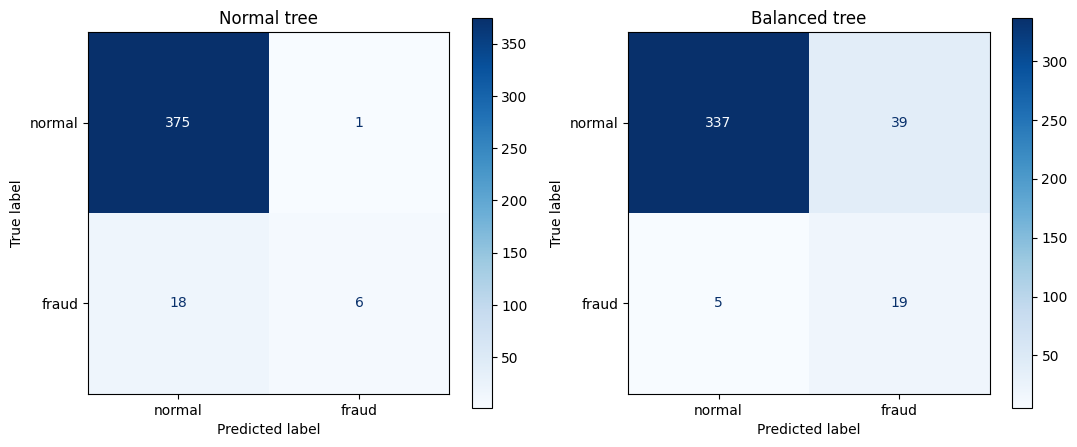

In [18]:
# ============================================================
# REAL-WORLD EXAMPLE: catch card fraud in 2,000 transactions.
# Only about 6% are fraud. Accuracy alone will trick us.
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, ConfusionMatrixDisplay

# ---------- 1. LOAD AND LOOK ----------
tx = pd.read_csv("transactions.csv")
print(tx["fraud"].value_counts())
print("Fraud:", round(tx["fraud"].mean() * 100, 1), "%")      # about 6%: very imbalanced

# ---------- 2. SPLIT (stratify = test data also has about 6% fraud) ----------
X = tx[["amount", "hour", "distance_from_home_km", "online"]]
y = tx["fraud"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Frauds in the test data:", y_test.sum(), "of", len(y_test))

# ---------- 3. THE LAZY MODEL: always says "normal" ----------
lazy = [0] * len(y_test)
print("\nLazy model  -> accuracy:", round(accuracy_score(y_test, lazy), 2),
      " recall:", recall_score(y_test, lazy))
# 94% accuracy, 0 frauds caught. Any real model must beat this.

# ---------- 4. A NORMAL TREE ----------
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
pred = tree.predict(X_test)
print("Tree        -> accuracy:", round(accuracy_score(y_test, pred), 2),
      " recall:", round(recall_score(y_test, pred), 2),
      " precision:", round(precision_score(y_test, pred), 2))
# Accuracy is great (95%), but recall is low: it misses most frauds.

# ---------- 5. A TREE THAT CARES ABOUT THE SMALL GROUP ----------
# class_weight="balanced" = "fraud is rare but important, pay more attention to it"
tree_bal = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42).fit(X_train, y_train)
pred_bal = tree_bal.predict(X_test)
print("Balanced    -> accuracy:", round(accuracy_score(y_test, pred_bal), 2),
      " recall:", round(recall_score(y_test, pred_bal), 2),
      " precision:", round(precision_score(y_test, pred_bal), 2))
# Accuracy goes DOWN, recall goes UP. For a bank, this is the better model.

# ---------- 6. SEE THE 4 BOXES FOR BOTH TREES ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["normal", "fraud"], cmap="Blues", ax=axes[0])
axes[0].set_title("Normal tree")
ConfusionMatrixDisplay.from_predictions(y_test, pred_bal, display_labels=["normal", "fraud"], cmap="Blues", ax=axes[1])
axes[1].set_title("Balanced tree")
plt.tight_layout()
plt.show()
# Bottom row = the real frauds. Left box = missed. Right box = caught.
# Balanced tree: catches about 19 of 24 frauds, but gives more false alarms (top right).

# ---------- 7. PICK THE MODEL ----------
# A false alarm = one SMS to the customer. A missed fraud = stolen money.
# So the cheap mistake is the false alarm. Choose the balanced tree.

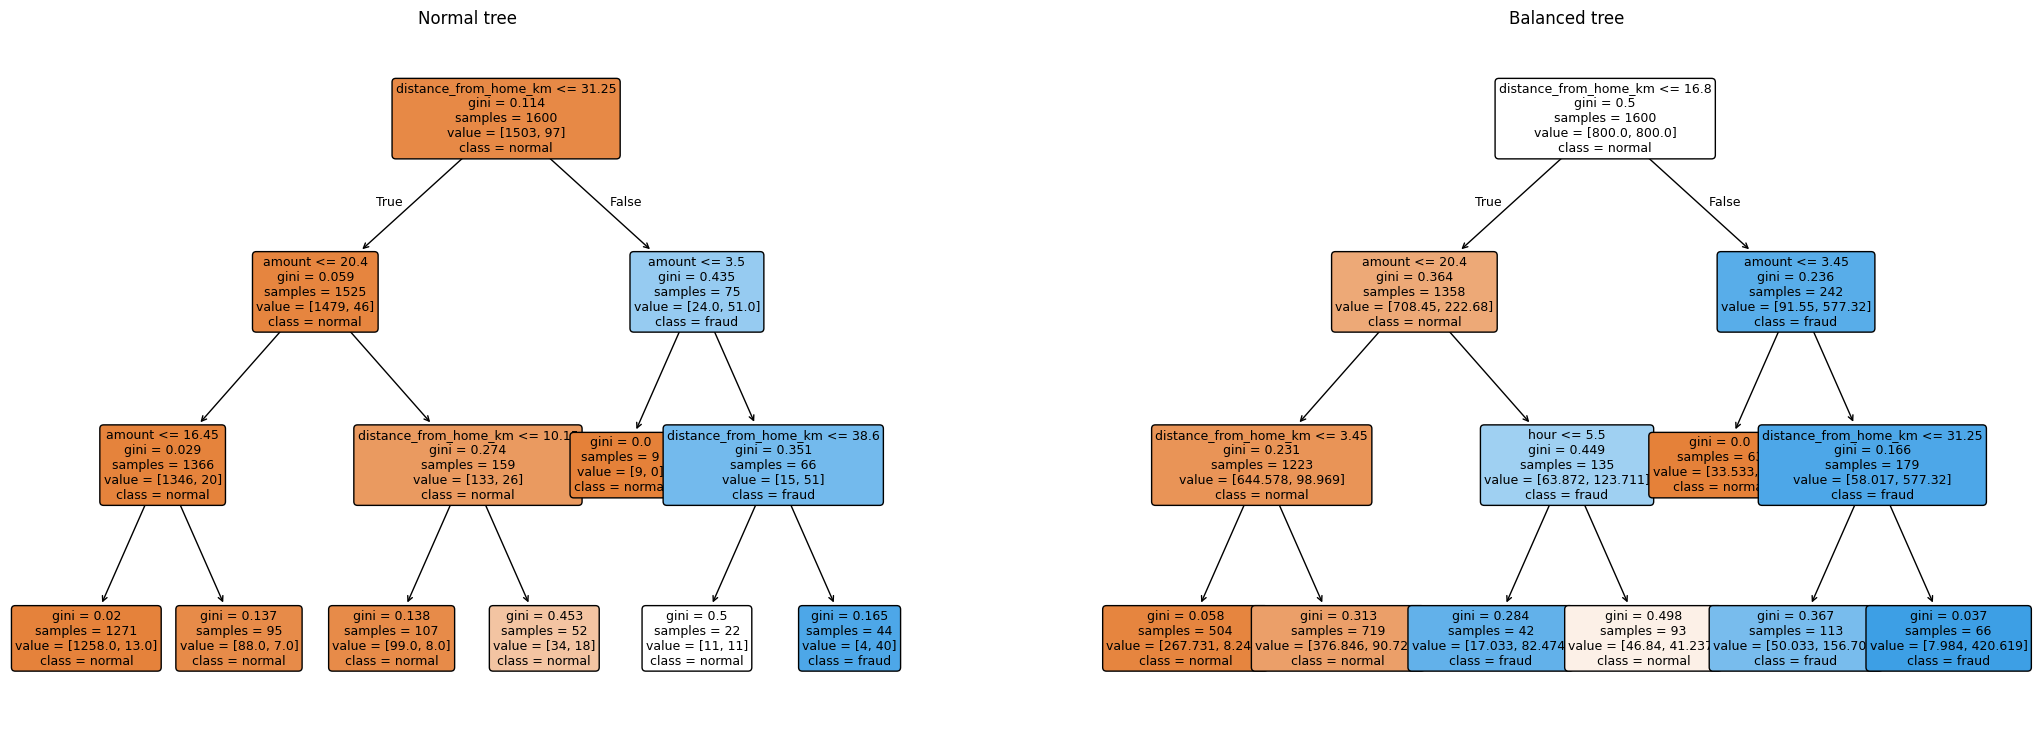

In [19]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(1, 2, figsize=(26, 9))
plot_tree(tree, feature_names=X.columns, class_names=["normal", "fraud"], filled=True, rounded=True, fontsize=9, ax=ax[0])
ax[0].set_title("Normal tree")
plot_tree(tree_bal, feature_names=X.columns, class_names=["normal", "fraud"], filled=True, rounded=True, fontsize=9, ax=ax[1])
ax[1].set_title("Balanced tree")
plt.show()

### The two trees: what changed?

Both trees use the same data and the same `max_depth=3`. Only one setting is different: `class_weight="balanced"`.

- **Normal tree:** only **1** of the 7 bottom boxes says **fraud**. It is very careful before it says "fraud", because only 6% of payments are fraud.
- **Balanced tree:** **3** of the 7 bottom boxes say **fraud**. We told it "fraud is rare but important", so it is quicker to say "fraud".

**Note:** in the balanced tree the `value` numbers look strange (like 800 and 800). This is the picnic vote: the tree counts each fraud as worth many normal payments, so the **fraud group and the normal group get the same total weight** (800 each, out of 1,600 training payments). You can ignore those numbers.

That is the whole difference: the balanced tree makes **more fraud answers**. The next part shows what this does to the confusion matrix.

## How to read the two confusion matrices

In each picture: **rows = what was really true**, **columns = what the tree said**.
The **bottom row** is the 24 payments that were **really fraud**. That is the row the bank cares about.

| Box | Meaning for the bank | Normal tree | Balanced tree |
|---|---|---|---|
| **correct normal** (top left) | normal payment, tree said normal | 375 | 337 |
| **false alarm** (top right) | normal payment, tree said fraud. The customer gets an SMS. | 1 | **39** |
| **missed fraud** (bottom left) | real fraud, tree said normal. **Money is stolen.** | **18** | 5 |
| **caught fraud** (bottom right) | real fraud, tree said fraud | 6 | **19** |

**Now the scores from those boxes:**

| Score | Normal tree | Balanced tree |
|---|---|---|
| **Accuracy** = (correct normal + caught) ÷ 400 | (375 + 6) ÷ 400 = **0.95** | (337 + 19) ÷ 400 = **0.89** |
| **Recall** = caught ÷ (caught + missed) | 6 ÷ 24 = **0.25** | 19 ÷ 24 = **0.79** |
| **Precision** = caught ÷ (caught + false alarms) | 6 ÷ 7 = **0.86** | 19 ÷ 58 = **0.33** |

**Why is the balanced tree better, if its accuracy is lower?**
- The normal tree lets **18 of 24 frauds** pass. That is 3 out of 4 thieves walking away.
- The balanced tree misses only **5**. But it sends **38 more** false alarms (39 instead of 1).
- A false alarm costs one SMS: "Was this you?". A missed fraud costs real money. So the bank is happy to accept more false alarms to catch more fraud.

**It is a trade-off:** more recall means more false alarms (lower precision). You choose the balance by asking: *which mistake is worse for this problem?*

> **Our answer to the bank:** "Use the balanced tree. It catches about 4 out of 5 frauds, instead of 1 out of 4. It will also flag about 39 normal payments by mistake, so send an SMS to check them, and do not block the card forever. Accuracy alone would have chosen the wrong model."

## The Complete Program

In [20]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score

# 1. Data: 8 people
people = pd.DataFrame({
    "monthly_income":       [50, 70, 90, 110, 140, 160, 180, 200],
    "has_defaulted_before": [1, 0, 0, 0, 0, 0, 1, 0],
    "approved":             [0, 0, 0, 1, 1, 1, 0, 1],
})

# 2. By hand: gini, and the weighted gini of each question
def gini(group):
    share_yes = group.mean()
    return 1 - (share_yes ** 2 + (1 - share_yes) ** 2)

def weighted_gini(data, question_is_true):
    left, right = data[question_is_true]["approved"], data[~question_is_true]["approved"]
    return len(left) / len(data) * gini(left) + len(right) / len(data) * gini(right)

questions = {"income <= " + str(t): people["monthly_income"] <= t for t in [60, 80, 100, 125, 150, 170, 190]}
questions["defaulted before"] = people["has_defaulted_before"] == 1
scores = {name: weighted_gini(people, mask) for name, mask in questions.items()}
print("By hand, best first question:", min(scores, key=scores.get), "-> weighted gini", round(min(scores.values()), 2))

# 3. With scikit-learn
features = ["monthly_income", "has_defaulted_before"]
tree = DecisionTreeClassifier(max_depth=2, random_state=42).fit(people[features], people["approved"])
print("scikit-learn, first question: monthly_income <=", tree.tree_.threshold[0])

# 4. Real project: 400 loans, split first, then check on the hidden test people
loans = pd.read_csv("loans.csv")
X = loans[["monthly_income", "loan_amount", "years_in_job", "has_defaulted_before"]]
y = loans["approved"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    "small tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "big tree (no limit)":  DecisionTreeClassifier(random_state=42),
    "random forest":        RandomForestClassifier(n_estimators=100, random_state=42),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, "| train:", round(accuracy_score(y_train, model.predict(X_train)), 2),
          "| test:", round(accuracy_score(y_test, pred), 2),
          "| recall:", round(recall_score(y_test, pred), 2),
          "| precision:", round(precision_score(y_test, pred), 2))

By hand, best first question: income <= 100 -> weighted gini 0.2
scikit-learn, first question: monthly_income <= 100.0
small tree (depth 3) | train: 0.83 | test: 0.78 | recall: 0.82 | precision: 0.79
big tree (no limit) | train: 1.0 | test: 0.74 | recall: 0.8 | precision: 0.75
random forest | train: 1.0 | test: 0.78 | recall: 0.84 | precision: 0.78


## Key Takeaways
- A **Decision Tree** is a list of yes/no questions. You can draw it and read it.
- The tree picks each question by trying **all** of them and keeping the **lowest weighted gini**.
- **Gini** = how mixed a box is. 0 = pure. 0.5 = half and half.
- `fit()` does this calculation for us, again and again, until the boxes are pure (or `max_depth` stops it).
- A deep tree **overfits**: 1.0 on train, worse on test. Keep it small. Report the **test** score.
- A **Random Forest** = many **big** trees that vote. Each tree memorises different cases, so the vote cancels the strange mistakes.
- `class_weight="balanced"` = each row of the small group counts more (like giving the 6 girls a bigger vote). It raises recall and lowers precision.
- From the **confusion matrix** (caught, missed, false alarms): **recall** = caught ÷ (caught + missed). **precision** = caught ÷ (caught + false alarms).
- **Accuracy can lie** on imbalanced data. Always compare with the **lazy model**.
- Choose the score by asking: **which mistake is worse?**
- **F1 score** = one number from recall and precision: 2 × precision × recall ÷ (precision + recall). It is low if either one is low. It works on any model, not only trees.